<a href="https://colab.research.google.com/github/Rohan46os/Video_gen_model/blob/main/diffusion_practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub
path = kagglehub.dataset_download("andrewmvd/face-mask-detection")

Using Colab cache for faster access to the 'face-mask-detection' dataset.


In [ ]:
path

'/kaggle/input/face-mask-detection'

In [ ]:
img1_path = "/kaggle/input/face-mask-detection/images/maksssksksss0.png"

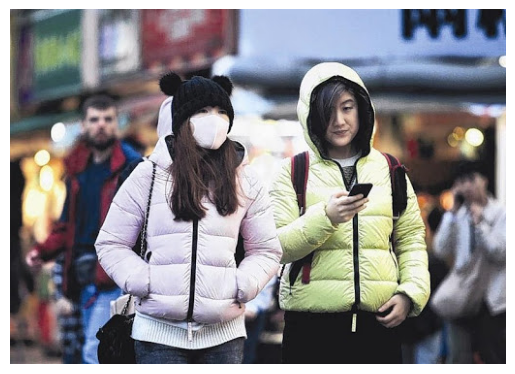

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open(img1_path)

plt.imshow(img)
plt.axis("off")
plt.show()

In [ ]:
from tqdm import tqdm
import os
import numpy as np
from PIL import Image

image_folder = "/kaggle/input/face-mask-detection/images"

vectors = []
filenames = []

files = os.listdir(image_folder)

for filename in tqdm(files):
    filepath = os.path.join(image_folder, filename)

    try:
        img = Image.open(filepath).convert("RGB")
        img = img.resize((128, 128))

        img_array = np.array(img, dtype=np.float32) / 255.0
        vectors.append(img_array.flatten())
        filenames.append(filename)

    except:
        pass

vectors = np.array(vectors)

print(vectors.shape)

100%|██████████| 853/853 [00:24<00:00, 34.80it/s]

(853, 49152)


In [ ]:
vectors.shape

(853, 49152)

In [ ]:
import torch

X = torch.tensor(vectors, dtype=torch.float32)

# (N, 49152) → (N, 128, 128, 3)
X = X.reshape(-1, 128, 128, 3)

# (N, H, W, C) → (N, C, H, W)
X = X.permute(0, 3, 1, 2)

print(X.shape)

torch.Size([853, 3, 128, 128])


In [ ]:
from torch.utils.data import TensorDataset, DataLoader

dataset = TensorDataset(X)

loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True
)

In [ ]:
dataset

**Now bulding a VAE which will predict MEAN and VARIANCE**

Building a cnn VAE encoder which predicts the mean and variance of all the vectors


In [ ]:
import torch
import torch.nn as nn


class Encoder(nn.Module):
    def __init__(self, latent_channels=4):
        super().__init__()

        self.encoder = nn.Sequential(
            # [B, 3, 128, 128]
            nn.Conv2d(3, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),

            # [B, 64, 64, 64]
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),

            # [B, 128, 32, 32]
            nn.Conv2d(128, 128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
        )

        # Produce mean and log-variance
        self.mu = nn.Conv2d(
            128, latent_channels,
            kernel_size=3, stride=1, padding=1
        )

        self.logvar = nn.Conv2d(
            128, latent_channels,
            kernel_size=3, stride=1, padding=1
        )

    def forward(self, x):
        h = self.encoder(x)

        mu = self.mu(h)
        logvar = self.logvar(h)

        return mu, logvar

In [ ]:
model = Encoder()

x = torch.randn(32, 3, 128, 128)

mu, logvar = model(x)

print("input   :", x.shape)
print("mu      :", mu.shape)
print("logvar  :", logvar.shape)

input   : torch.Size([32, 3, 128, 128])
mu      : torch.Size([32, 4, 32, 32])
logvar  : torch.Size([32, 4, 32, 32])


In [ ]:
std  =torch.randn_like(logvar*5) #

z = mu + torch.exp(logvar/2)*torch.randn_like(logvar)

print(z.shape)

torch.Size([32, 4, 32, 32])


logvar

   ↓
   
  exp()

variance

   ↓

  sqrt()

standard deviation

   ↓

μ + σ ε

   ↓

z

In [ ]:
std.shape

torch.Size([32, 4, 32, 32])